In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display first five rows
print("TAXIS DATASET")
print(df.head())

# Display dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

TAXIS DATASET
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Si

In [3]:
# Check missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Display columns that contain missing values
print("\nColumns with Missing Values:")
print(df.columns[df.isnull().any()].tolist())

# Display total number of missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with Missing Values:
['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']

Total Missing Values:
186


In [4]:
# Create a copy of the dataset
df_clean = df.copy()

# Fill missing numerical values with median
for column in df_clean.select_dtypes(include=np.number).columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Fill missing categorical values with mode
for column in df_clean.select_dtypes(include="object").columns:
    if df_clean[column].isnull().any():
        df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:")
print(df_clean.shape)

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Cleaned Dataset Shape:
(6433, 14)


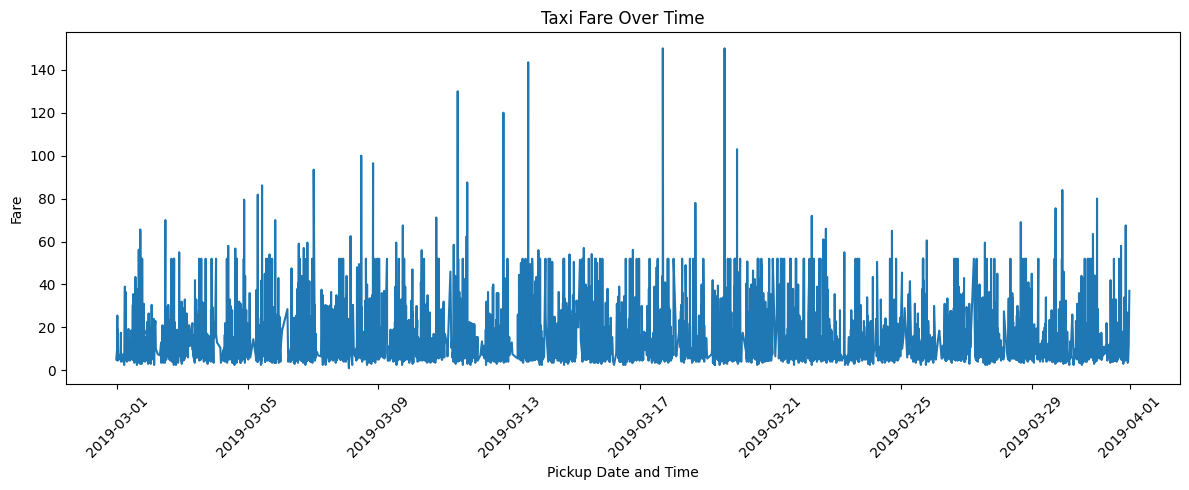

In [5]:
# Convert pickup column to datetime format
df_clean['pickup'] = pd.to_datetime(df_clean['pickup'], errors='coerce')

# Remove rows with missing pickup timestamps
line_data = df_clean.dropna(subset=['pickup', 'fare'])

# Sort data by pickup time
line_data = line_data.sort_values('pickup')

# Create line chart
plt.figure(figsize=(12, 5))
plt.plot(line_data['pickup'], line_data['fare'])

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Date and Time')
plt.ylabel('Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

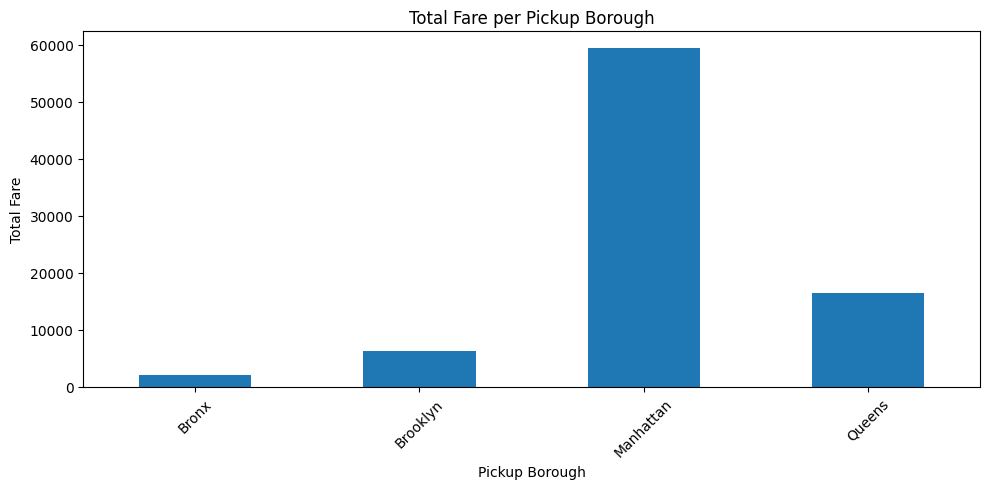

In [6]:
# Calculate total fare for each pickup borough
borough_fare = df_clean.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 5))
borough_fare.plot(kind='bar')

plt.title('Total Fare per Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

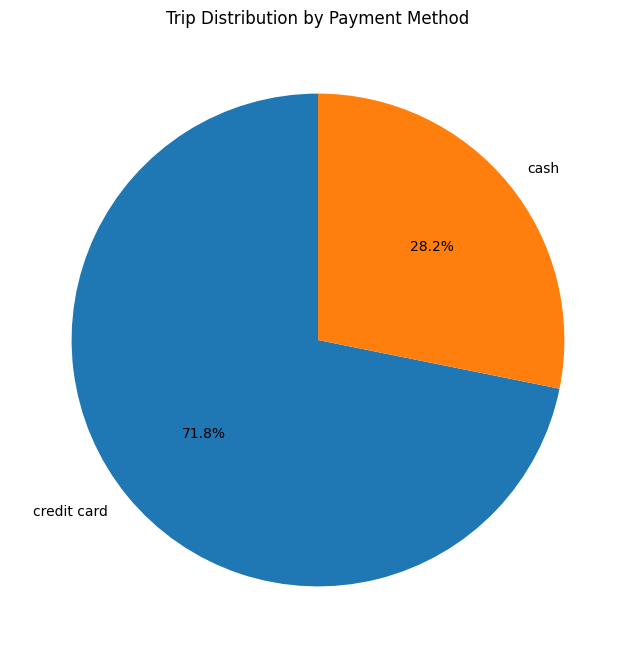

In [7]:
# Count trips by payment method
payment_counts = df_clean['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Trip Distribution by Payment Method')
plt.show()

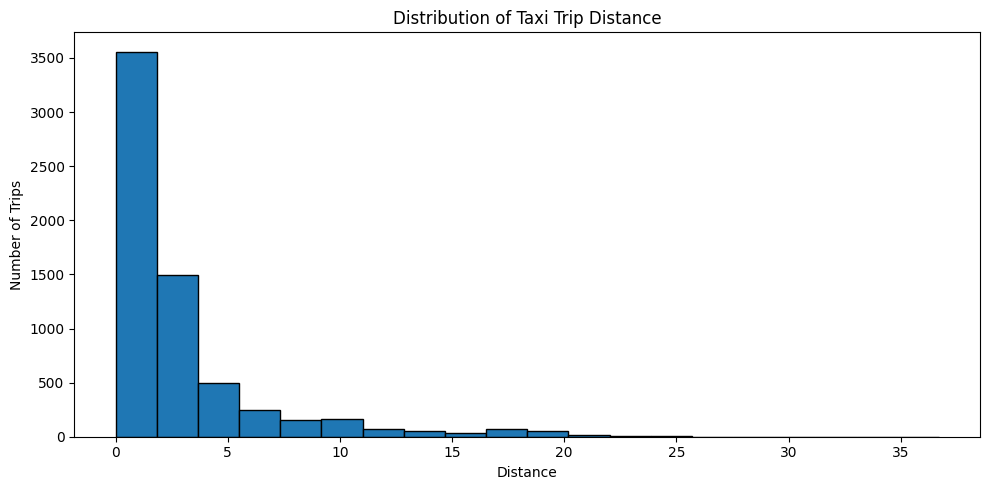

In [8]:
# Create histogram for trip distance
plt.figure(figsize=(10, 5))

plt.hist(df_clean['distance'].dropna(), bins=20, edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')

plt.tight_layout()
plt.show()

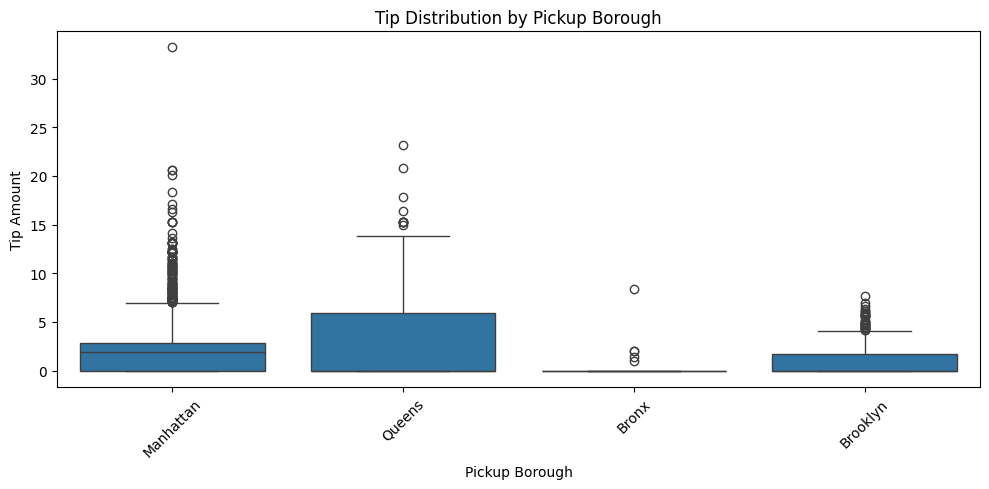

In [9]:
# Create box plot for tip distribution by pickup borough
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_clean, x='pickup_borough', y='tip')

plt.title('Tip Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

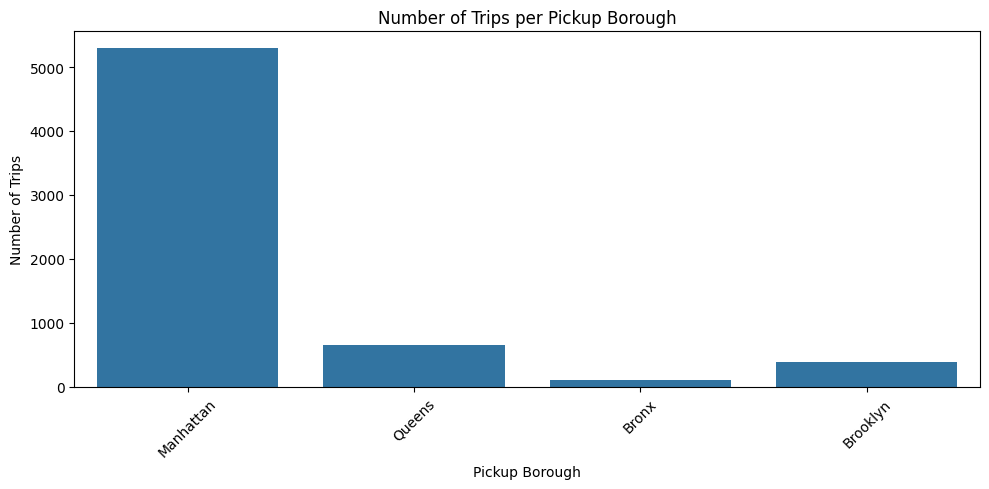

In [10]:
# Count the number of trips in each pickup borough
plt.figure(figsize=(10, 5))

sns.countplot(data=df_clean, x='pickup_borough')

plt.title('Number of Trips per Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

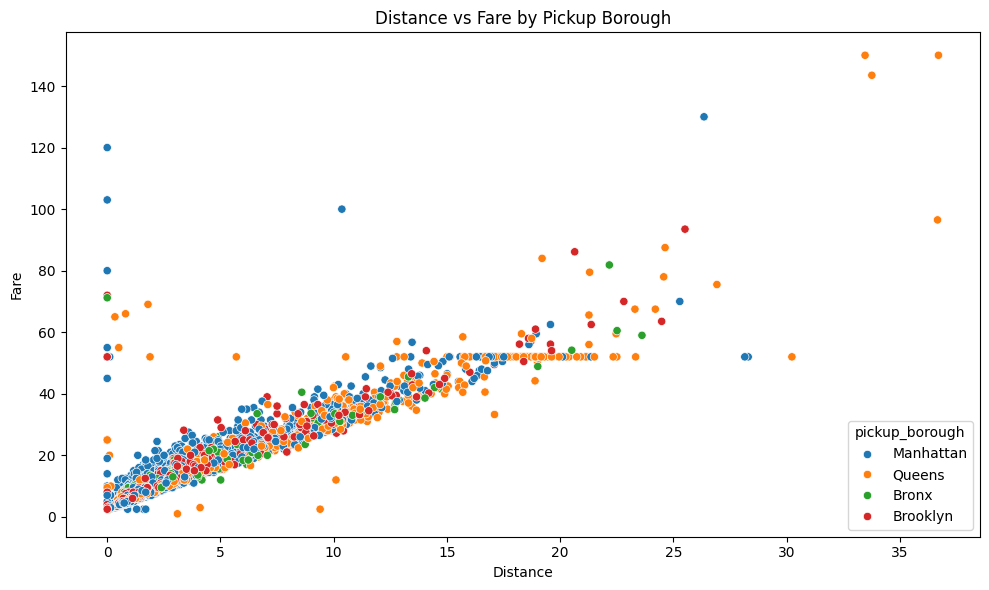

In [11]:
# Scatter plot showing distance vs fare
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

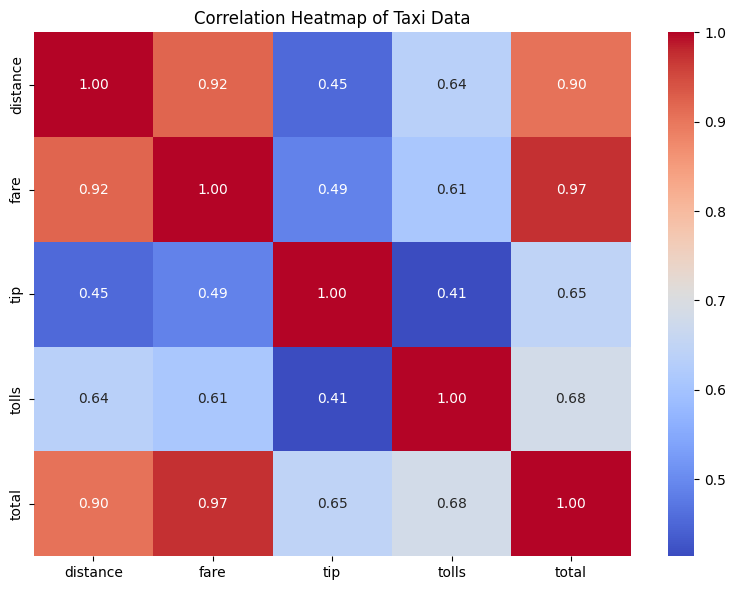

In [12]:
# Select numerical columns for correlation
numeric_data = df_clean[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation
correlation = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Taxi Data')
plt.tight_layout()
plt.show()

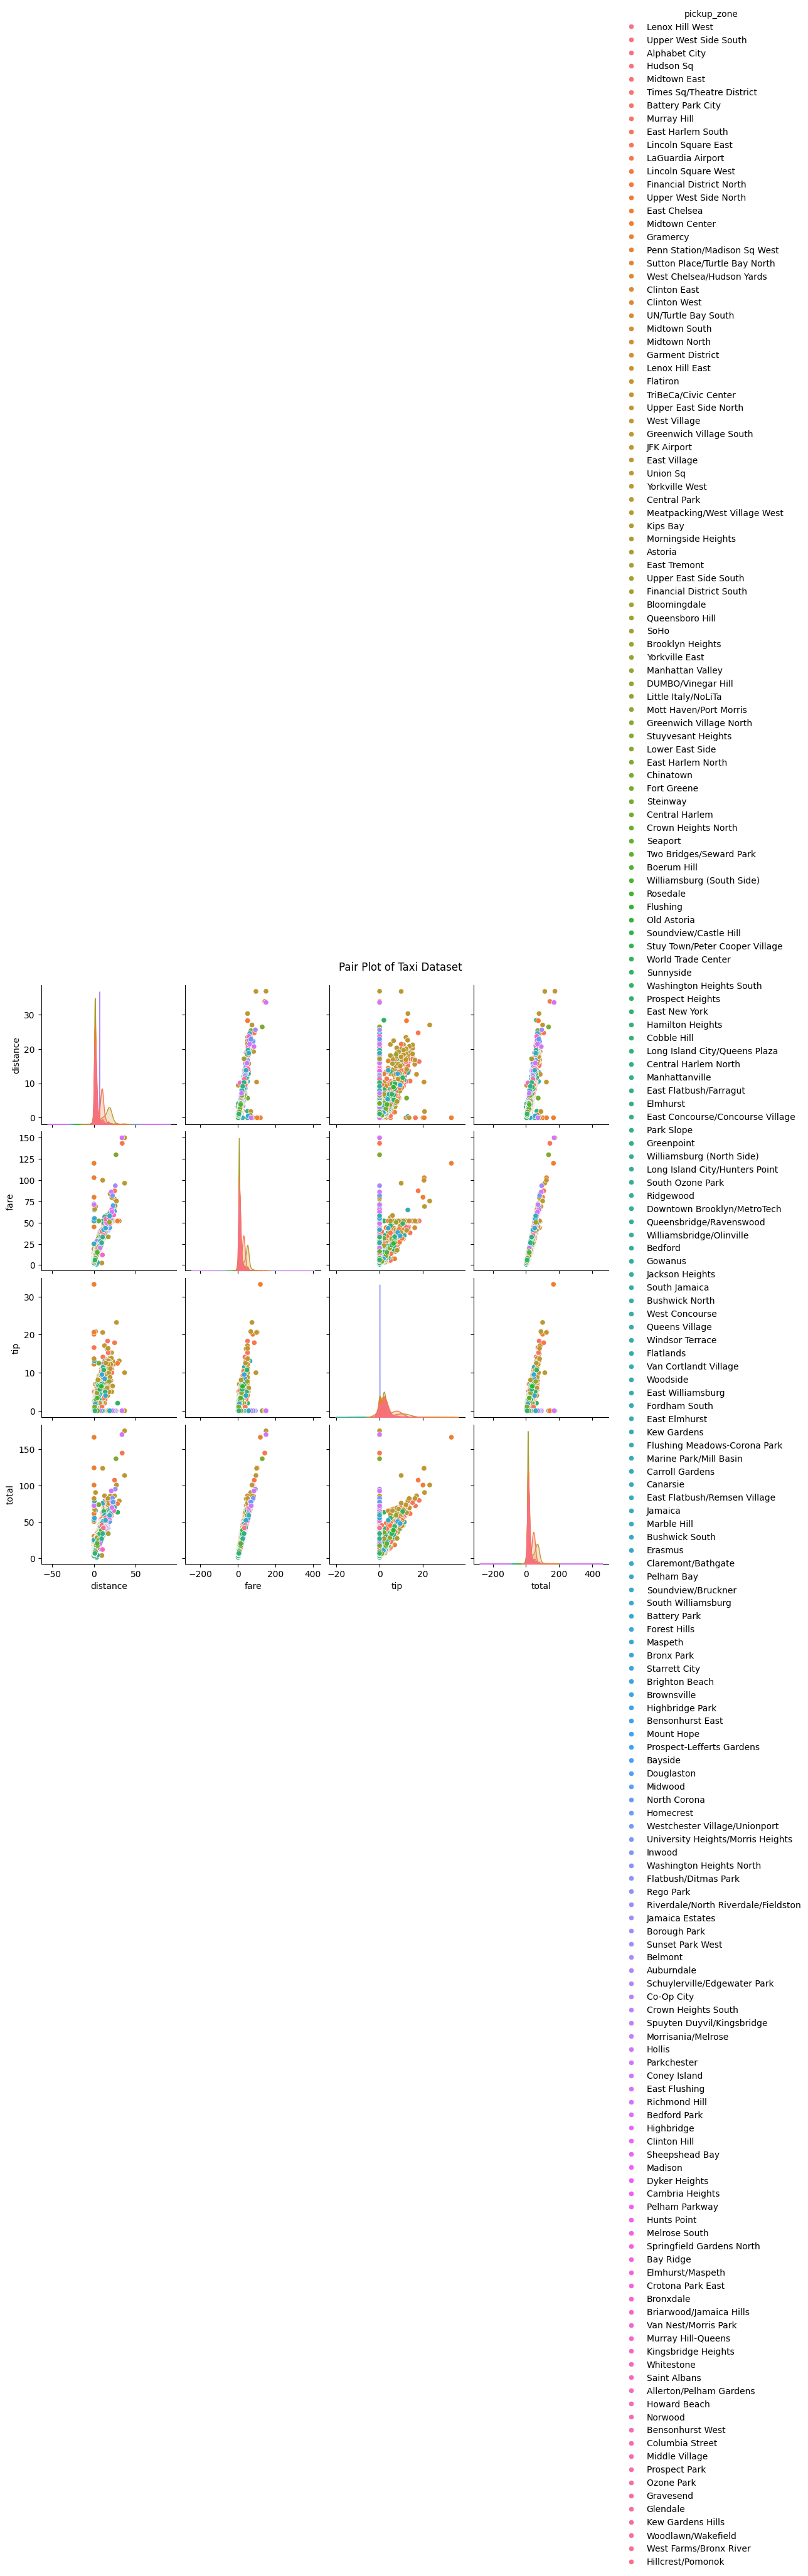

In [13]:
# Create pair plot
sns.pairplot(
    df_clean,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.suptitle('Pair Plot of Taxi Dataset', y=1.02)
plt.show()

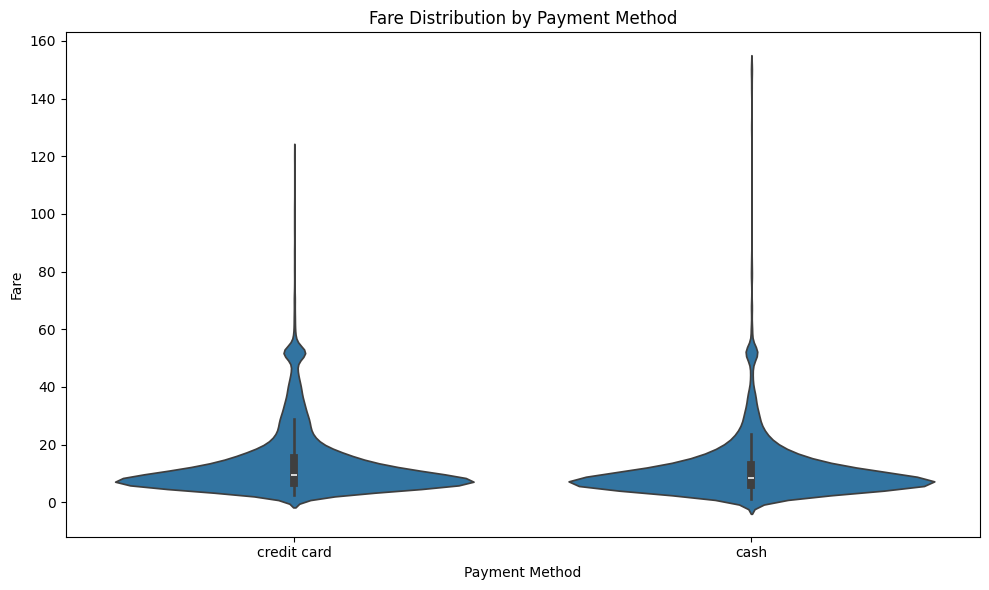

In [14]:
# Create violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_clean,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

In [15]:
# Check missing values in the cleaned dataset
print("Final Missing Values:")
print(df_clean.isnull().sum())

# Display final dataset information
print("\nFinal Dataset Shape:")
print(df_clean.shape)

print("\nFinal Dataset:")
display(df_clean.head())

print("\nDataset Information:")
df_clean.info()

Final Missing Values:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Final Dataset Shape:
(6433, 14)

Final Dataset:


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6433 non-null   object        
 10  pickup_zone      6433 non-null   object        
 11  dropoff_zone     6433 non-null   object        
 12  pickup_borough   6433 non-null   object        
 13  dropoff_borough  6433 non-null   object        
dtypes: datetime64[ns](